# Problem 1
## (a)
$$ \kappa^{\mathrm{rel}}_{f_1}(x_0) = \kappa^{\mathrm{abs}}_{f_1}(x_0) \left|\frac{x_0}{f_1(x_0)}\right| = ||f^{'}_1(x_0)||\left|\frac{x_0}{f_1(x_0)}\right|$$
$$ = 3(x_0 - 2a)^2 \left|\frac{x_0}{(x_0-2a)^3}\right| = 3 \left|\frac{x_0}{x_0-2a}\right|$$
$$ \kappa^{\mathrm{rel}}_{f_1}(10^7) = 3\left|\frac{10^7}{2}\right| = 1.5 \cdot 10^7 $$

In [69]:
a = 10**7/2 - 1
x_0 = 10**7
f_1_expanded = lambda x: x**3 - 6*a*x**2 + 12*a**2*x - 8*a**2
f_1_factorized = lambda x: (x-2*a)**3
print(f'expanded version: \t {f_1_expanded(x_0)}\nfactorized version:  {f_1_factorized(x_0)}')

expanded version: 	 9.999992000002004e+20
factorized version:  8.0


## (b)

In [70]:
f_2 = lambda x: 1/(x - (x**2 - 1)**0.5)
f_2(x_0)

19884107.85185185

$$ f_2 = \frac{1}{x-\sqrt{x^2-1}} = \frac{x+\sqrt{x^2-1}}{(x+\sqrt{x^2-1})(x-\sqrt{x^2-1})} = {x+\sqrt{x^2-1}} $$

In [71]:
f_2_reform = lambda x: x + (x**2-1)**0.5
f_2_reform(x_0)

19999999.999999948

## (c)
$$ \kappa^{\mathrm{rel}}_{f_3}(x_0) = \kappa^{\mathrm{abs}}_{f_3}(x_0) \left|\frac{x_0}{f_3(x_0)}\right| = ||f^{'}_3(x_0)|| \left|\frac{x_0}{1-\sqrt{1-x_0^2}}\right|$$
$$ = \left|\frac{x_0}{\sqrt{1-x_0^2}}\cdot\frac{x_0}{1-\sqrt{1-x_0^2}}\right| = \left|\frac{x_0^2}{\sqrt{1-x_0^2} - 1 + x_0^2}\right|$$

Set $s := \sqrt{1-x_0^2} \in (0,1)$ for $0 < |x_0| < 1$, so that $x_0^2 = 1 - s^2$:

$$ = \frac{1-s^2}{s-s^2} = \frac{(1-s)(1+s)}{s(1-s)} = \frac{1+s}{s} = \frac{1+\sqrt{1-x_0^2}}{\sqrt{1-x_0^2}}$$

Hence

$$ \lim_{x_0 \to 0} \kappa^{\mathrm{rel}}_{f_3}(x_0) = \frac{1+\sqrt{1}}{\sqrt{1}} = 2 $$
To avoid cancellation, multiply numerator and denominator by $1+\sqrt{1-x^2}$:

$$ f_3(x) = 1-\sqrt{1-x^2} = \frac{\left(1-\sqrt{1-x^2}\right)\left(1+\sqrt{1-x^2}\right)}{1+\sqrt{1-x^2}} = \frac{1-(1-x^2)}{1+\sqrt{1-x^2}} = \frac{x^2}{1+\sqrt{1-x^2}} =: {f}_{3,reform}(x)$$

In [72]:
from matplotlib import pyplot as plt
import numpy as np

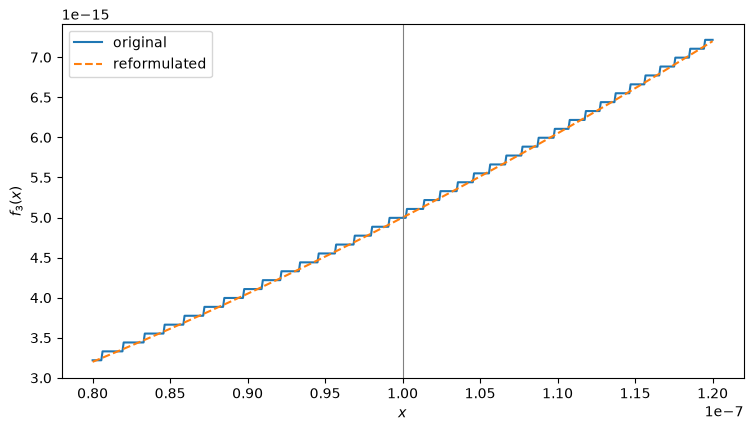

In [73]:
f_3 = lambda x: 1 - np.sqrt(1 - x**2)
f_3_reform = lambda x: x**2 / (1 + np.sqrt(1 - x**2))

x_0 = 1e-7
t_grid = np.linspace(x_0 - 0.2e-7, x_0 + 0.2e-7, 500)

y = f_3(t_grid)
v = f_3_reform(t_grid)

fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.plot(t_grid, y, color="tab:blue", label="original")
ax.plot(t_grid, v, color="tab:orange", linestyle="--", label="reformulated")
ax.axvline(x_0, color="gray", linewidth=0.8)
ax.set_xlabel("$x$")
ax.set_ylabel("$f_3(x)$")
ax.legend()
plt.show()

## (d)

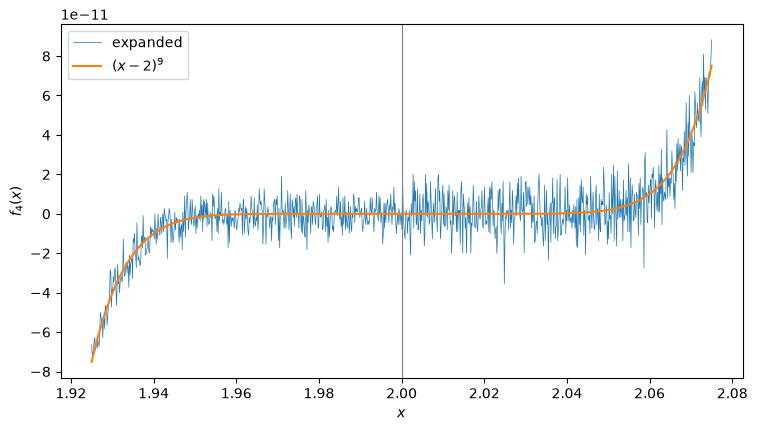

In [74]:
f_4 = lambda x: (x**9 - 18*x**8 + 144*x**7 - 672*x**6 + 2016*x**5
                 - 4032*x**4 + 5376*x**3 - 4608*x**2 + 2304*x - 512)
f_4_reform = lambda x: (x - 2)**9

t_grid = np.linspace(1.925, 2.075, 1000)
y = f_4(t_grid)
v = f_4_reform(t_grid)

fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.plot(t_grid, y, color="tab:blue", label="expanded", linestyle="-", lw=0.5)
ax.plot(t_grid, v, color="tab:orange", linestyle="-", label="$(x-2)^9$")
ax.axvline(2, color="gray", linewidth=0.8)
ax.set_xlabel("$x$")
ax.set_ylabel("$f_4(x)$")
ax.legend()
plt.show()

## (e)
$$ f_5(x) = \frac{1}{1+2x} - \frac{1-x}{1+x}$$
$$ f_5(x) = \frac{(1+x) - (1-x)(1+2x)}{(1+2x)(1+x)} = \frac{1 + x - 1 - x + 2x^2}{(1+2x)(1+x)} = \frac{2x^2}{(1+2x)(1+x)} =: \tilde{f}_5(x)$$

With $g(x) := (1+2x)(1+x) = 1 + 3x + 2x^2$ we have $f_5 = 2x^2/g$, hence

$$ \frac{f_5'(x)}{f_5(x)} = \frac{2}{x} - \frac{g'(x)}{g(x)} = \frac{2}{x} - \frac{3+4x}{1+3x+2x^2}$$
and therefore
$$ \kappa^{\mathrm{rel}}_{f_5}(x) = \left|\frac{f_5'(x)\,x}{f_5(x)}\right| = \left|2 - \frac{x(3+4x)}{1+3x+2x^2}\right| = \left|\frac{2+3x}{(1+2x)(1+x)}\right|$$
$$ \lim_{x \to 0} \kappa^{\mathrm{rel}}_{f_5}(x) = 2 $$


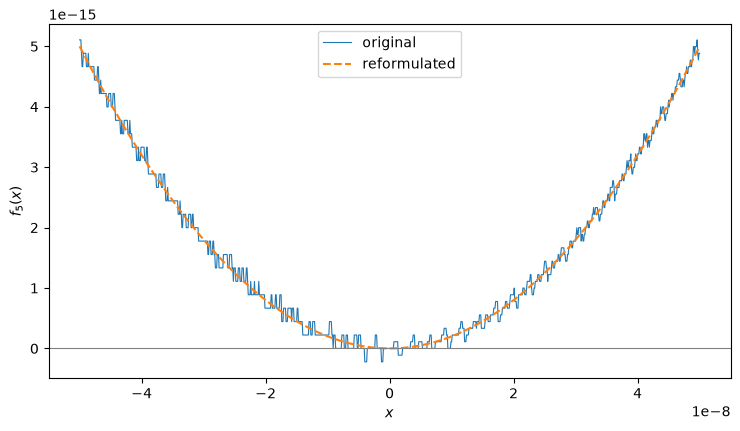

In [75]:
f_5 = lambda x: 1/(1 + 2*x) - (1 - x)/(1 + x)
f_5_reform = lambda x: 2*x**2 / ((1 + 2*x)*(1 + x))

t_grid = np.linspace(-5e-8, 5e-8, 1001)
y = f_5(t_grid)
v = f_5_reform(t_grid)

fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.plot(t_grid, y, color="tab:blue", lw=0.8, label="original")
ax.plot(t_grid, v, color="tab:orange", linestyle="--", label="reformulated")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("$x$")
ax.set_ylabel("$f_5(x)$")
ax.legend()
plt.show()

# Problem 2
## (a)

In [76]:
def constr_A(n):
    A = np.zeros(shape = (n,n))
    for i in range(n):
        A[i,i] = 3
        try:
            A[i,i+1] = 2
            A[i+1,i] = 2
        except:
            pass
        try:
            A[i,i+2] = 1
            A[i+2,i] = 1
        except:
            pass
    return A/9

In [77]:
constr_A(5)

array([[0.33333333, 0.22222222, 0.11111111, 0.        , 0.        ],
       [0.22222222, 0.33333333, 0.22222222, 0.11111111, 0.        ],
       [0.11111111, 0.22222222, 0.33333333, 0.22222222, 0.11111111],
       [0.        , 0.11111111, 0.22222222, 0.33333333, 0.22222222],
       [0.        , 0.        , 0.11111111, 0.22222222, 0.33333333]])

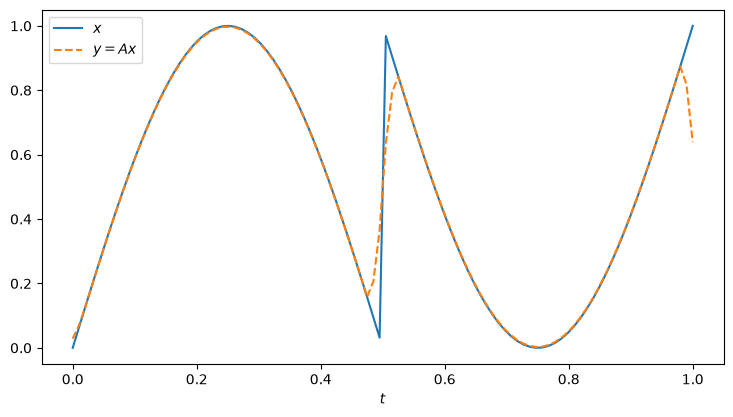

In [78]:
n = 100
A = constr_A(n)
t = np.linspace(0, 1, n)
x = np.sin(2*np.pi*t) + (t > 0.5)
y = A @ x

fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.plot(t, x, color="tab:blue", label="$x$")
ax.plot(t, y, color="tab:orange", linestyle="--", label="$y = Ax$")
ax.set_xlabel("$t$")
ax.legend()
plt.show()

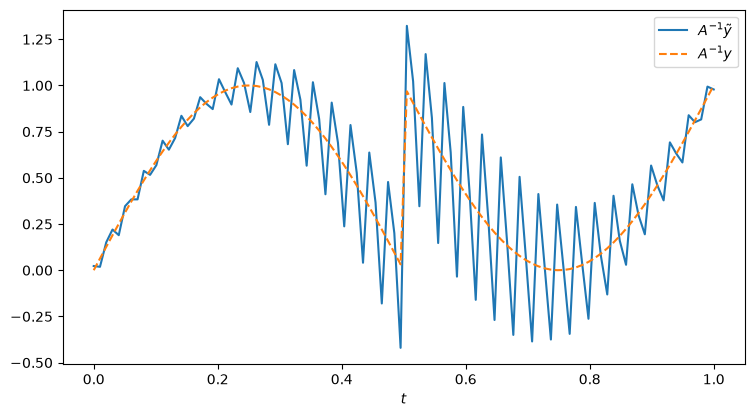

In [79]:
A_inv = np.linalg.inv(A)
rng = np.random.default_rng(42)
sigma = 1e-3
eps = sigma * rng.standard_normal(n)
y_tilde = y + eps
x_tilde = A_inv @ y_tilde
x = A_inv @ y
fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.plot(t, x_tilde, color="tab:blue", label=rf"$A^{{-1}}\tilde y$")
ax.plot(t, x, color="tab:orange", linestyle="--", label=r"$A^{-1}y$")
ax.set_xlabel("$t$")
ax.legend()
plt.show()

## (d)

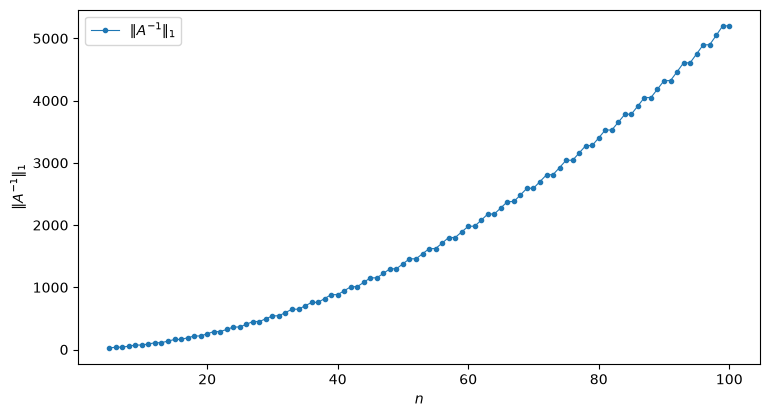

In [80]:
ns = np.arange(5, 101)
norms = np.array([np.linalg.norm(np.linalg.inv(constr_A(n)), 1) for n in ns])

fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.plot(ns, norms, color="tab:blue", marker=".", lw=0.8, label=r"$\|A^{-1}\|_1$")
ax.set_xlabel("$n$")
ax.set_ylabel(r"$\|A^{-1}\|_1$")
ax.legend()
plt.show()